# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Недосіка Назарій'      # прізвище та ім'я
GROUP        = 'ШІ-32'      # шифр групи, наприклад СШІ-31
NUMBER       = 14       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Недосіка Назарій | ШІ-32 | номер 14


In [3]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 14   ·   Недосіка Назарій   ·   ШІ-32

   Ринок:  Zhytomyr
   Товар:  молоко   (у наборі даних: Milk - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [5]:
# Завдання 1. Підготовка ряду
import pandas as pd

df = pd.read_csv("ціни_україна_2014_2017.csv")

data = df[(df["ринок"] == MARKET) & (df["товар"] == GOOD)].copy()

data["date"] = pd.to_datetime(
    dict(year=data["рік"], month=data["місяць"], day=1)
)

monthly_grid = pd.date_range("2014-03-01", "2017-12-01", freq="MS")

ts = data.set_index("date")["ціна"].sort_index().reindex(monthly_grid)
ts.index.name = "date"

missing = ts[ts.isna()].index

print("Місяців у сітці:", len(ts))
print("Місяців із вимірами:", ts.count())
print("Кількість пропусків:", ts.isna().sum())
print("Пропущений місяць:", missing.strftime("%Y-%m").tolist())

for date in missing:
    count = len(df[(df["рік"] == date.year) & (df["місяць"] == date.month)])
    print("Записів за пропущений місяць у всьому наборі:", count)

print("\nПерші значення ряду:")
print(ts.head())


Місяців у сітці: 46
Місяців із вимірами: 45
Кількість пропусків: 1
Пропущений місяць: ['2017-08']
Записів за пропущений місяць у всьому наборі: 0

Перші значення ряду:
date
2014-03-01    7.8300
2014-04-01    7.8300
2014-05-01    7.7033
2014-06-01    7.8233
2014-07-01    7.8300
Freq: MS, Name: ціна, dtype: float64


**Висновок до завдання 1:**

Сформовано часовий ряд цін на молоко для ринку Zhytomyr за 2014-2017 роки. Ряд містить 46 місяців, з яких 45 мають значення. Виявлено один пропуск - серпень 2017 року, оскільки дані за цей місяць відсутні в усьому наборі.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [6]:
# Завдання 2. Заповнення пропуску

missing_date = ts[ts.isna()].index[0]

ffill_value = ts.ffill().loc[missing_date]
linear_value = ts.interpolate(method="linear").loc[missing_date]
bfill_value = ts.bfill().loc[missing_date]

ts_filled = ts.interpolate(method="linear")

print("Пропущений місяць:", missing_date.strftime("%Y-%m"))
print(f"Перенесення попереднього значення: {ffill_value:.4f}")
print(f"Лінійна інтерполяція: {linear_value:.4f}")
print(f"Перенесення наступного значення: {bfill_value:.4f}")
print("Обраний метод: лінійна інтерполяція")
print("Пропусків після заповнення:", ts_filled.isna().sum())

Пропущений місяць: 2017-08
Перенесення попереднього значення: 15.7100
Лінійна інтерполяція: 15.8867
Перенесення наступного значення: 16.0633
Обраний метод: лінійна інтерполяція
Пропусків після заповнення: 0


**Висновок до завдання 2:**

Для серпня 2017 року отримано три значення: перенесення попереднього - 15.7100, лінійна інтерполяція - 15.8867, перенесення наступного - 16.0633. Обрано лінійну інтерполяцію, оскільки вона враховує сусідні значення. Заповнення неприпустиме при тривалій відсутності спостережень, наприклад, для Криму та Севастополя після березня 2014 року.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

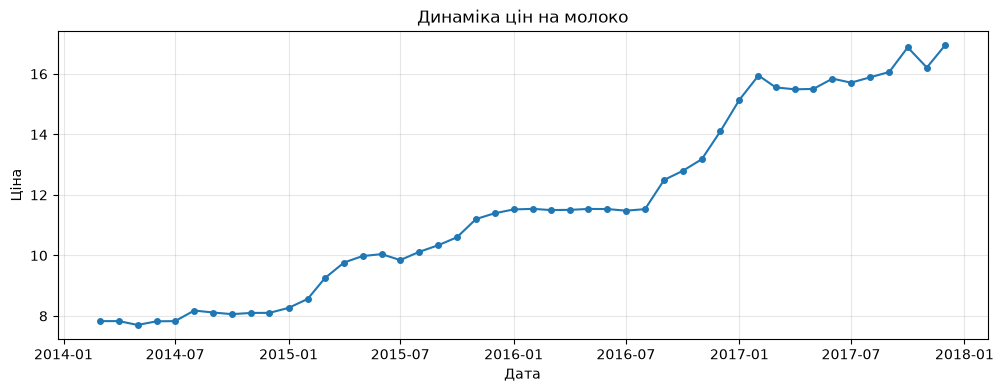

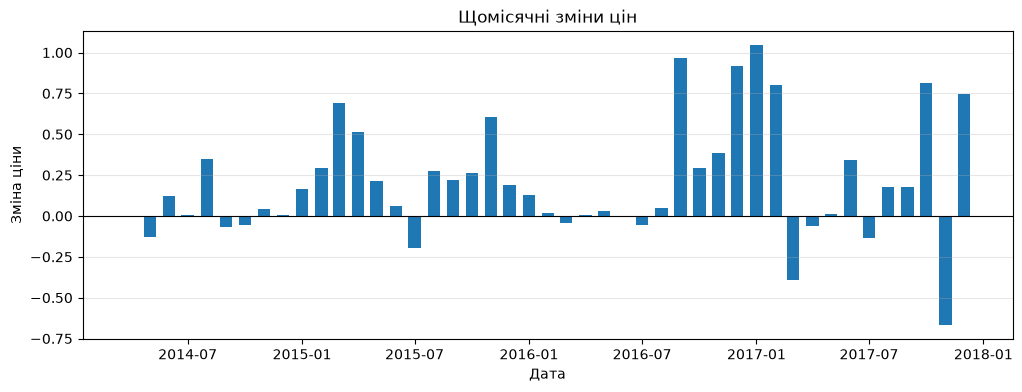

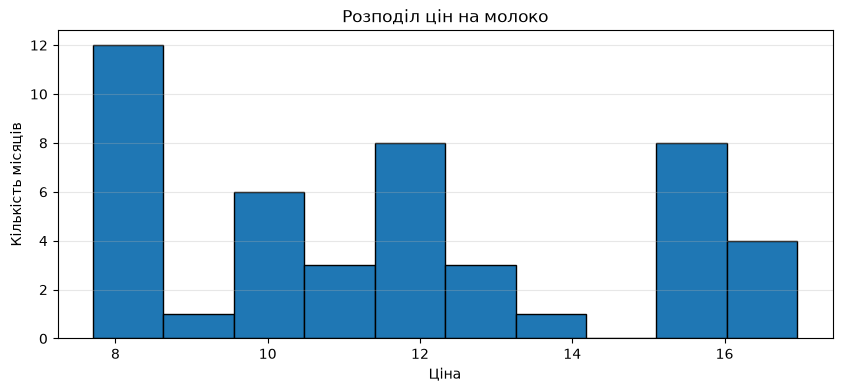

Найбільше зростання: 2017-01 1.0466
Найбільше падіння: 2017-11 -0.6667


In [7]:
# Завдання 3. Візуальна розвідка
import matplotlib.pyplot as plt

series = ts_filled.astype(float)
changes = series.diff().dropna()

plt.figure(figsize=(12, 4))
plt.plot(series.index, series.values, marker="o", markersize=4)
plt.title("Динаміка цін на молоко")
plt.xlabel("Дата")
plt.ylabel("Ціна")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(12, 4))
plt.bar(changes.index, changes.values, width=20)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Щомісячні зміни цін")
plt.xlabel("Дата")
plt.ylabel("Зміна ціни")
plt.grid(axis="y", alpha=0.3)
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(series.values, bins=10, edgecolor="black")
plt.title("Розподіл цін на молоко")
plt.xlabel("Ціна")
plt.ylabel("Кількість місяців")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Найбільше зростання:", changes.idxmax().strftime("%Y-%m"),
      round(changes.max(), 4))
print("Найбільше падіння:", changes.idxmin().strftime("%Y-%m"),
      round(changes.min(), 4))


**Висновок до завдання 3:**

Побудовано три графіки з лінійними шкалами. Лінійний графік показує загальне зростання цін, стовпчиковий - величину щомісячних змін, гістограма - частоту різних цінових значень. Такі форми обрано для відображення динаміки, порівняння змін і розподілу. Неочікуваною знахідкою стала стабільність цін протягом більшої частини 2016 року, після якої відбулося різке зростання.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

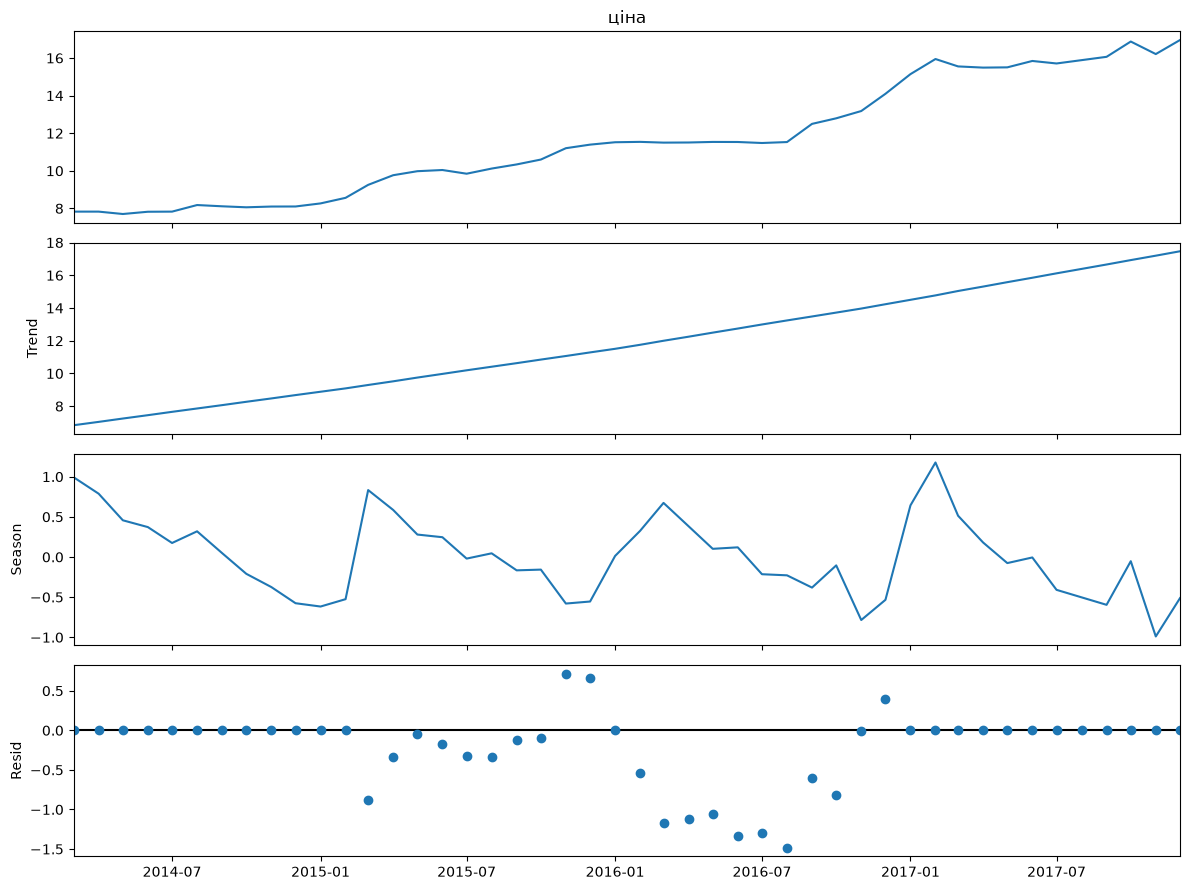

Сила сезонності Fs: 0.3490
Сила тренду Ft: 0.9762
Порогове значення: 0.6
Сезонність: слабка
Тренд: виражений


In [10]:
# Завдання 4. Розкладання на складові
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

stl = STL(ts_filled, period=12, robust=True).fit()

fig = stl.plot()
fig.set_size_inches(12, 9)
plt.tight_layout()
plt.show()

resid = stl.resid
seasonal = stl.seasonal
trend = stl.trend

Fs = max(0, 1 - np.var(resid) / np.var(seasonal + resid))
Ft = max(0, 1 - np.var(resid) / np.var(trend + resid))

print(f"Сила сезонності Fs: {Fs:.4f}")
print(f"Сила тренду Ft: {Ft:.4f}")
print("Порогове значення: 0.6")
print("Сезонність:", "виражена" if Fs >= 0.6 else "слабка")
print("Тренд:", "виражений" if Ft >= 0.6 else "слабкий")


**Висновок до завдання 4:**

Методом STL ряд розкладено на тренд, сезонність і залишок. Сила сезонності Fs = 0.3490, що нижче порогу 0.6, тому сезонність слабка. Сила тренду Ft = 0.9762 свідчить про виражений висхідний тренд. Отже, основним чинником зміни цін є тренд, а не сезонність.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

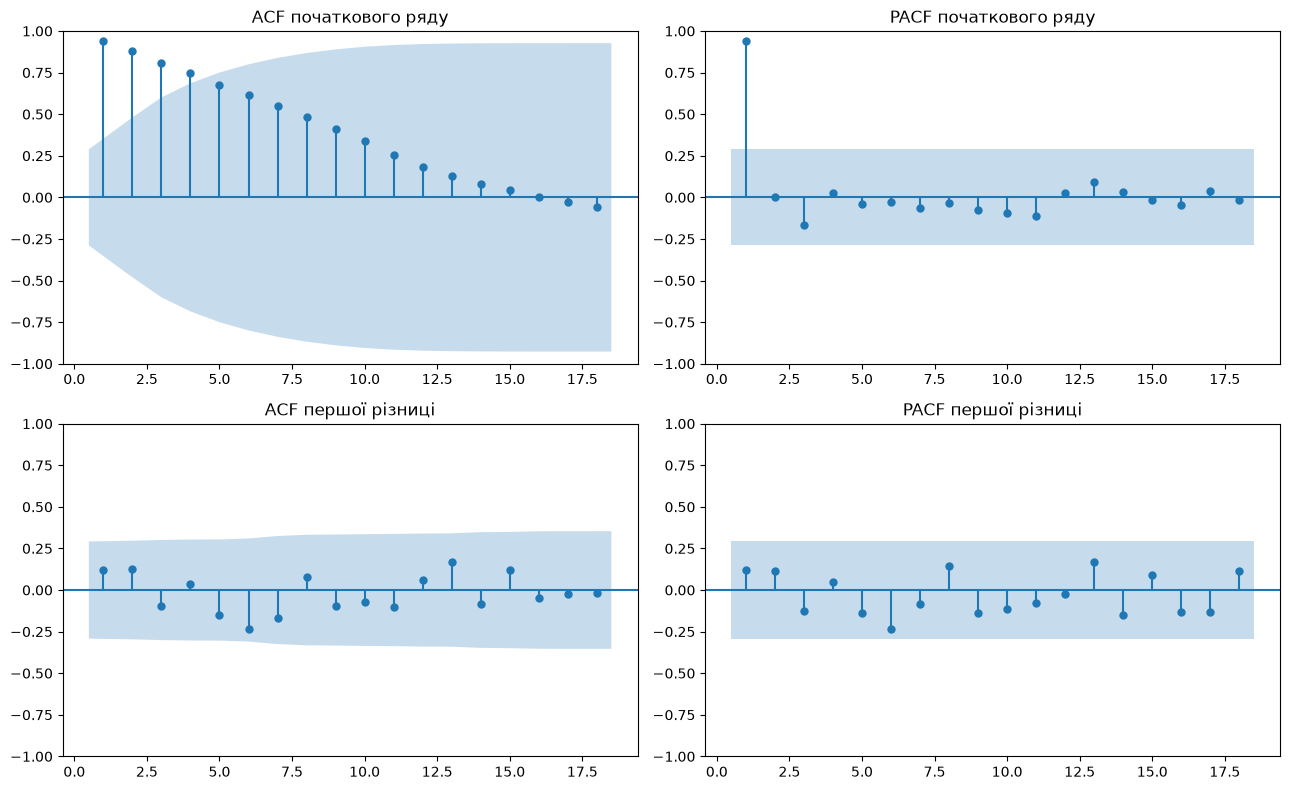

C:\Users\nazus\AppData\Local\Temp\ipykernel_12480\3475083874.py:29: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(data, autolag="AIC")[1]
C:\Users\nazus\AppData\Local\Temp\ipykernel_12480\3475083874.py:29: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(data, autolag="AIC")[1]


,Ряд,ADF p-value,KPSS p-value,ADF,KPSS
0,Початковий ряд,0.9879,0.01,Нестаціонарний,Нестаціонарний
1,Перша різниця,0.0000,0.10,Стаціонарний,Стаціонарний


In [ ]:
# Завдання 5. Стаціонарність
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
import warnings

ts_diff = ts_filled.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

plot_acf(ts_filled, lags=18, ax=axes[0, 0], zero=False)
axes[0, 0].set_title("ACF початкового ряду")

plot_pacf(ts_filled, lags=18, ax=axes[0, 1], zero=False)
axes[0, 1].set_title("PACF початкового ряду")

plot_acf(ts_diff, lags=18, ax=axes[1, 0], zero=False)
axes[1, 0].set_title("ACF першої різниці")

plot_pacf(ts_diff, lags=18, ax=axes[1, 1], zero=False)
axes[1, 1].set_title("PACF першої різниці")

plt.tight_layout()
plt.show()

results = []

for name, data in [("Початковий ряд", ts_filled),
                   ("Перша різниця", ts_diff)]:
    adf_p = adfuller(data, autolag="AIC")[1]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_p = kpss(data, regression="c", nlags="auto")[1]

    results.append({
        "Ряд": name,
        "ADF p-value": round(adf_p, 4),
        "KPSS p-value": round(kpss_p, 4),
        "ADF": "Стаціонарний" if adf_p < 0.05 else "Нестаціонарний",
        "KPSS": "Стаціонарний" if kpss_p >= 0.05 else "Нестаціонарний"
    })

display(pd.DataFrame(results))

**Висновок до завдання 5:**

Початковий ряд нестаціонарний: ADF p = 0.9879, KPSS p = 0.01. Після першого диференціювання ряд стає стаціонарним: ADF p = 0.0000, KPSS p = 0.10. Графіки ACF і PACF підтверджують зменшення автокореляції. Обидва тести узгоджуються між собою, тому додаткові перевірки не потрібні. Для моделі ARIMA обрано d = 1.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

Ретроспективна перевірка: 7 фолдів по 3 кроки


,MAE,RMSE,MAPE (%)
Наївний,0.5087,0.7662,3.4116
Сезонний наївний,3.0157,3.2055,20.4286
Середнє,4.1254,4.3493,27.9243
Дрейф,0.4811,0.5852,3.3022


Випадковий поділ 75/25


,MAE,RMSE,MAPE (%)
Наївний,0.2589,0.3821,2.0833
Сезонний наївний,2.0706,2.6947,15.1109
Середнє,2.2880,3.0526,16.2328
Дрейф,0.3227,0.4128,2.7713


Відношення похибок: випадковий / ретроспективний


,MAE,RMSE,MAPE (%)
Наївний,0.51,0.50,0.61
Сезонний наївний,0.69,0.84,0.74
Середнє,0.55,0.70,0.58
Дрейф,0.67,0.71,0.84


Найкращий базис за MAE: Дрейф


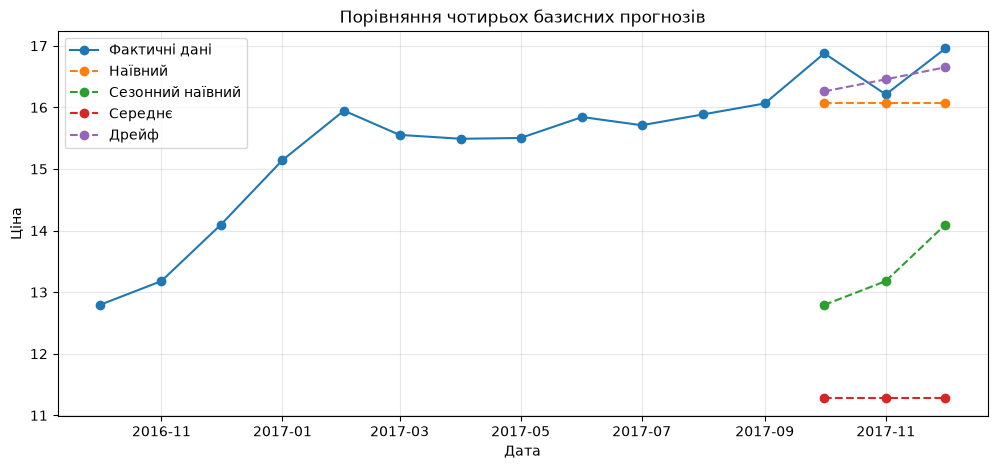

In [12]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

y = ts_filled.to_numpy(dtype=float)
methods = ["Наївний", "Сезонний наївний", "Середнє", "Дрейф"]

def predict(train_idx, target):
    past = train_idx[train_idx < target]
    values = y[past]

    naive = values[-1]
    seasonal_idx = past[past % 12 == target % 12]
    seasonal = y[seasonal_idx[-1]] if len(seasonal_idx) else naive
    mean = values.mean()

    drift = naive
    if len(past) > 1:
        slope = (values[-1] - values[0]) / (past[-1] - past[0])
        drift = naive + slope * (target - past[-1])

    return np.array([naive, seasonal, mean, drift])

def metrics(actual, predicted):
    errors = predicted - actual[:, None]
    mae = np.mean(np.abs(errors), axis=0)
    rmse = np.sqrt(np.mean(errors ** 2, axis=0))
    mape = np.mean(np.abs(errors / actual[:, None]), axis=0) * 100
    return pd.DataFrame({
        "MAE": mae, "RMSE": rmse, "MAPE (%)": mape
    }, index=methods)

actual_cv = []
predicted_cv = []

for fold in range(7):
    origin = len(y) - 21 + fold * 3
    train_idx = np.arange(origin)

    for target in range(origin, origin + 3):
        actual_cv.append(y[target])
        predicted_cv.append(predict(train_idx, target))

cv_results = metrics(np.array(actual_cv), np.array(predicted_cv))

indices = np.random.RandomState(42).permutation(len(y))
n_test = int(np.ceil(len(y) * 0.25))
test_idx = np.sort(indices[:n_test])
train_idx = np.sort(indices[n_test:])

random_predictions = np.array([
    predict(train_idx, target) for target in test_idx
])
random_results = metrics(y[test_idx], random_predictions)

print("Ретроспективна перевірка: 7 фолдів по 3 кроки")
display(cv_results.round(4))

print("Випадковий поділ 75/25")
display(random_results.round(4))

print("Відношення похибок: випадковий / ретроспективний")
display((random_results / cv_results).round(2))

best = cv_results["MAE"].idxmin()
print("Найкращий базис за MAE:", best)

origin = len(y) - 3
future_idx = np.arange(origin, len(y))
forecasts = np.array([
    predict(np.arange(origin), target) for target in future_idx
])

plt.figure(figsize=(12, 5))
plt.plot(ts_filled.index[-15:], y[-15:],
         marker="o", label="Фактичні дані")

for i, method in enumerate(methods):
    plt.plot(ts_filled.index[-3:], forecasts[:, i],
             marker="o", linestyle="--", label=method)

plt.title("Порівняння чотирьох базисних прогнозів")
plt.xlabel("Дата")
plt.ylabel("Ціна")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Висновок до завдання 6:**

Порівняно чотири базисні прогнози. Найкращим виявився метод дрейфу: MAE = 0.4811, RMSE = 0.5852, MAPE = 3.30%, оскільки ряд має виражений висхідний тренд. Найгіршим став метод середнього. При випадковому поділі 75/25 похибка MAE методу дрейфу виявилася меншою в 1.49 раза. Це свідчить, що випадковий поділ може давати надто оптимістичну оцінку для часових рядів.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

Порівняння моделей:


,MAE,RMSE,MAPE (%)
Наївний,0.5087,0.7662,3.4116
Сезонний наївний,3.0157,3.2055,20.4286
Середнє,4.1254,4.3493,27.9243
Дрейф,0.4811,0.5852,3.3022
"ARIMA(1,1,1)",0.3438,0.4548,2.3082


Найкращий базис: Дрейф
MAE базису: 0.4811
MAE ARIMA: 0.3438

Самостійно обраний порядок: ARIMA(0,1,0) з дрейфом


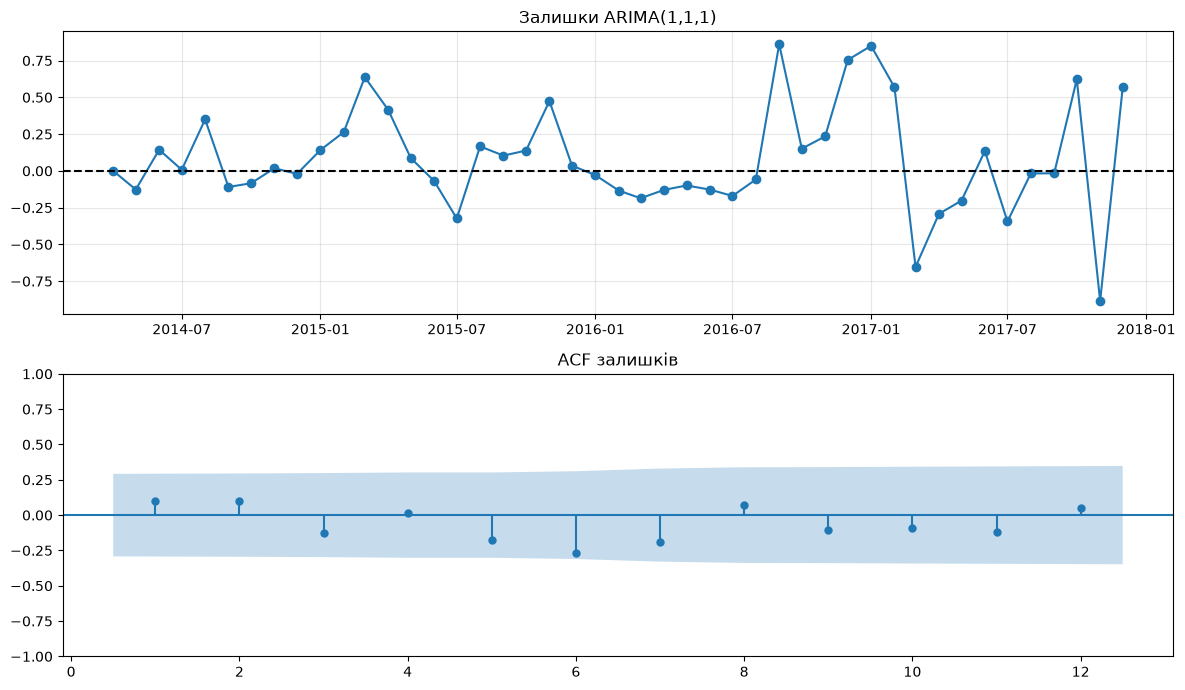

Ljung-Box p-value: 0.3901
Залишкова автокореляція: не виявлена


In [13]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
import warnings

actual_arima = []
predicted_arima = []

for fold in range(7):
    origin = len(ts_filled) - 21 + fold * 3
    train = ts_filled.iloc[:origin]
    test = ts_filled.iloc[origin:origin + 3]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = ARIMA(train, order=(1, 1, 1)).fit()

    forecast = model.forecast(steps=3)

    actual_arima.extend(test.values)
    predicted_arima.extend(forecast.values)

actual_arima = np.array(actual_arima)
predicted_arima = np.array(predicted_arima)

mae = np.mean(np.abs(actual_arima - predicted_arima))
rmse = np.sqrt(np.mean((actual_arima - predicted_arima) ** 2))
mape = np.mean(np.abs((actual_arima - predicted_arima) / actual_arima)) * 100

comparison = cv_results.copy()
comparison.loc["ARIMA(1,1,1)"] = [mae, rmse, mape]

print("Порівняння моделей:")
display(comparison.round(4))

best_baseline = cv_results["MAE"].idxmin()
print("Найкращий базис:", best_baseline)
print("MAE базису:", round(cv_results.loc[best_baseline, "MAE"], 4))
print("MAE ARIMA:", round(mae, 4))

print("\nСамостійно обраний порядок: ARIMA(0,1,0) з дрейфом")

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    final_model = ARIMA(ts_filled, order=(1, 1, 1)).fit()

residuals = final_model.resid.iloc[1:]

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(residuals.index, residuals.values, marker="o")
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Залишки ARIMA(1,1,1)")
axes[0].grid(alpha=0.3)

plot_acf(residuals, lags=12, ax=axes[1], zero=False)
axes[1].set_title("ACF залишків")

plt.tight_layout()
plt.show()

ljung_p = acorr_ljungbox(residuals, lags=[10], return_df=True)["lb_pvalue"].iloc[0]

print("Ljung-Box p-value:", round(ljung_p, 4))
print("Залишкова автокореляція:",
      "виявлена" if ljung_p < 0.05 else "не виявлена")


**Висновок до завдання 7:**

Модель ARIMA(1,1,1) показала MAE = 0.3438, RMSE = 0.4548, MAPE = 2.31%, перевершивши найкращий базис - метод дрейфу (MAE = 0.4811). Альтернативою обрано ARIMA(0,1,0) з дрейфом, оскільки ACF і PACF першої різниці не мають значущих піків. Тест Льюнга-Бокса (p = 0.3901) не виявив значущої автокореляції залишків. Отже, модель ARIMA(1,1,1) є придатною для прогнозування.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Дата зміни: 2017-01
t-статистика: -16.6011
|t|: 16.6011
Середнє до: 10.1077
Середнє після: 15.9319
Різниця: 5.8242
p-value: 0.000000
p-value з поправкою Бонферроні: 0.000000
Статистично значуща за поправкою: Так


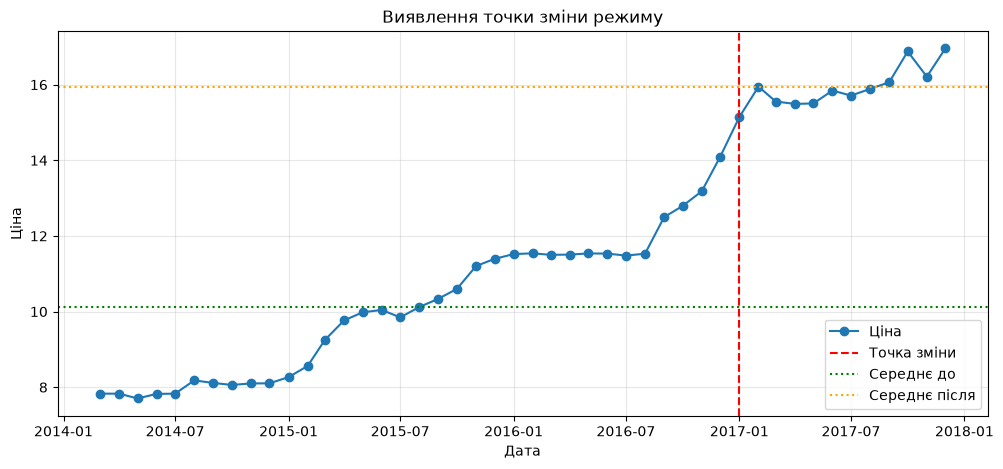

In [14]:
# Завдання 8. Точка зміни режиму
from scipy.stats import ttest_ind
import numpy as np
import matplotlib.pyplot as plt

series = ts_filled.astype(float)
min_size = 8
results = []

for i in range(min_size, len(series) - min_size + 1):
    before = series.iloc[:i]
    after = series.iloc[i:]

    t_stat, p_value = ttest_ind(before, after, equal_var=False)

    results.append({
        "date": series.index[i],
        "t": t_stat,
        "p": p_value,
        "mean_before": before.mean(),
        "mean_after": after.mean()
    })

best = max(results, key=lambda x: abs(x["t"]))
adjusted_p = min(best["p"] * len(results), 1.0)

print("Дата зміни:", best["date"].strftime("%Y-%m"))
print(f"t-статистика: {best['t']:.4f}")
print(f"|t|: {abs(best['t']):.4f}")
print(f"Середнє до: {best['mean_before']:.4f}")
print(f"Середнє після: {best['mean_after']:.4f}")
print(f"Різниця: {best['mean_after'] - best['mean_before']:.4f}")
print(f"p-value: {best['p']:.6f}")
print(f"p-value з поправкою Бонферроні: {adjusted_p:.6f}")
print("Статистично значуща за поправкою:",
      "Так" if adjusted_p < 0.05 else "Ні")

plt.figure(figsize=(12, 5))
plt.plot(series.index, series.values, marker="o", label="Ціна")
plt.axvline(best["date"], color="red", linestyle="--",
            label="Точка зміни")
plt.axhline(best["mean_before"], color="green",
            linestyle=":", label="Середнє до")
plt.axhline(best["mean_after"], color="orange",
            linestyle=":", label="Середнє після")
plt.title("Виявлення точки зміни режиму")
plt.xlabel("Дата")
plt.ylabel("Ціна")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Висновок до завдання 8:**

Виявлено точку зміни рівня ряду - січень 2017 року. Значення |t| = 16.6011, середня ціна до зміни - 10.1077, після - 15.9319. Зміна статистично значуща (p < 0.05), хоча на результат впливає загальний тренд. На відміну від сезонності, підвищення рівня зберігається протягом 2017 року, а не повторюється щорічно.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

Завдання 9. Рецензія на чужий аналіз
**Виявлені методологічні помилки:**

1. **Комірка 4** - пропуски перевіряються без повної місячної сітки. Через це не виявлено серпень 2017 року, що порушує часову послідовність.
2. **Комірка 6** - зростання цін прирівнюється до зниження купівельної спроможності без аналізу доходів населення. Висновок необґрунтований.
3. **Комірка 8** - порівнюються абсолютні MAE товарів із різними рівнями цін. Це створює некоректне порівняння точності.
4. **Комірка 10** - кореляція між областями трактується як причинний зв'язок. Кореляція не доводить причинності.
5. **Комірка 12** - наявність сезонної складової STL вважається доказом сезонності. Не перевірено її силу.
6. **Комірка 14** - неправильно інтерпретовано ADF. При p > 0.05 немає підстав вважати ряд стаціонарним.
7. **Комірка 14** - застосовано подвійне диференціювання без перевірки першої різниці. Це може спотворити структуру ряду.
8. **Комірка 16** - заявлено поріг аномалій 2 стандартні відхилення, але використано 1.3. Це призводить до хибного визначення аномалій.
9. **Комірка 18** - використано випадковий поділ часового ряду, що порушує хронологію прогнозування.
10. **Комірка 18** - тестові значення сортуються за величиною, а прогноз порівнюється з ними без відповідності дат. MAE стає недостовірною.
11. **Комірка 20** - використано ARIMA(2,2,1) без обґрунтування та перевірки. Надійність прогнозу не підтверджена.
12. **Комірка 22** - обрізано вертикальну вісь стовпчикового графіка, що візуально перебільшує зростання цін.

**Виправлення трьох найсерйозніших помилок:**

- **Комірка 4** - створити повну місячну сітку, виявити пропущений серпень 2017 року та заповнити його обґрунтованим методом.
- **Комірка 14** - правильно трактувати ADF і перевірити стаціонарність першої різниці перед вибором параметра d.
- **Комірка 18** - замінити випадковий поділ на ретроспективну перевірку з рухомим початком, прогнозувати майбутні місяці та порівнювати значення за відповідними датами.

**Висновок до завдання 9:**

 Попри відсутність помилок виконання коду, аналіз містить суттєві методологічні недоліки. Найнебезпечніші з них стосуються підготовки даних, перевірки стаціонарності та оцінювання прогнозів, що робить підсумкові висновки ненадійними.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [15]:
# Завдання 10. Експорт ряду для Orange
export_df = ts_filled.rename("price").rename_axis("date").reset_index()

export_df["date"] = export_df["date"].dt.strftime("%Y-%m-%d")

export_df.to_csv("ряд_для_orange.csv", index=False, sep=",", encoding="utf-8")

check = pd.read_csv("ряд_для_orange.csv")

print("Кількість рядків:", len(check))
print("Кількість пропусків:", check.isna().sum().sum())
print("Назви стовпців:", check.columns.tolist())
print("\nПерші 5 рядків:")
display(check.head())

assert len(check) == 46
assert check.isna().sum().sum() == 0
assert check.columns.tolist() == ["date", "price"]

print("\nФайл успішно збережено!")

Кількість рядків: 46
Кількість пропусків: 0
Назви стовпців: ['date', 'price']

Перші 5 рядків:


,date,price
0,2014-03-01,7.8300
1,2014-04-01,7.8300
2,2014-05-01,7.7033
3,2014-06-01,7.8233
4,2014-07-01,7.8300



Файл успішно збережено!


**Висновок до завдання 10:**

Підготовлений часовий ряд експортовано у файл ряд_для_orange.csv. Файл містить 46 рядків даних, два стовпці - date і price. Пропущених значень немає, формат дат YYYY-MM-DD, кодування UTF-8. Дані готові до використання в Orange.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

**Висновок до завдання 11:**

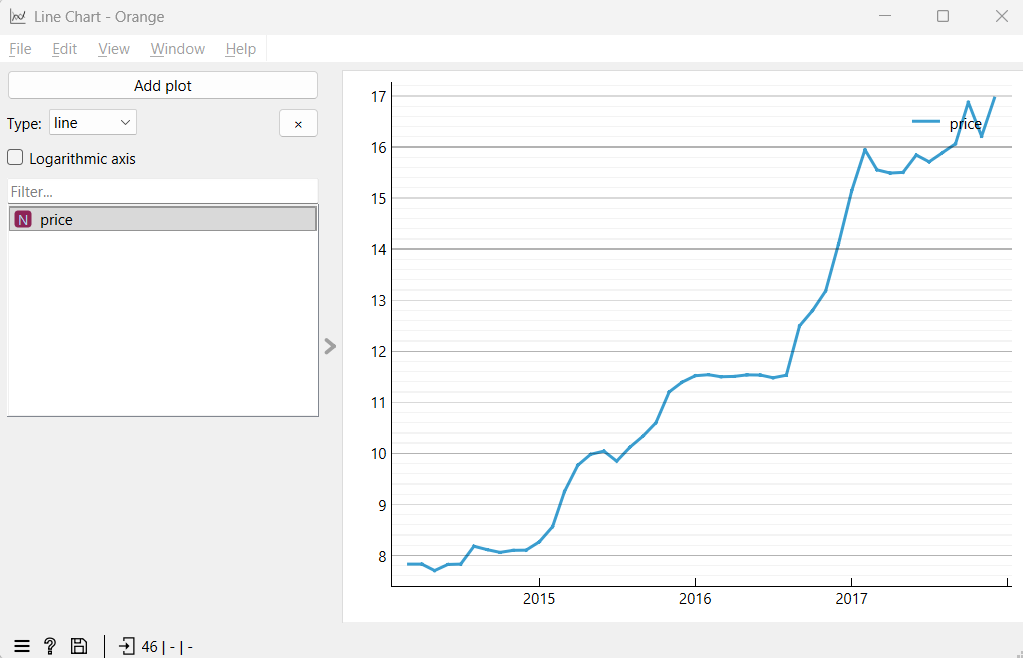

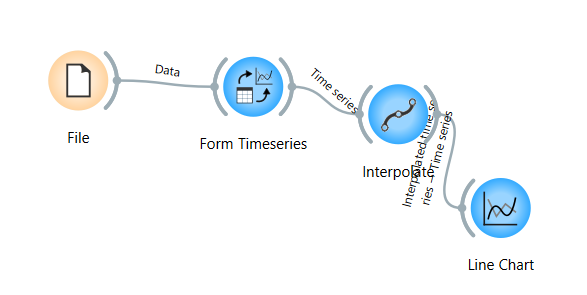

В Orange побудовано потік обробки часового ряду з 46 спостережень. Дані завантажено без пропусків, часову змінну визначено правильно. Графік Orange збігається з графіком Python із завдання 3 та підтверджує зростання цін протягом 2014-2017 років.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

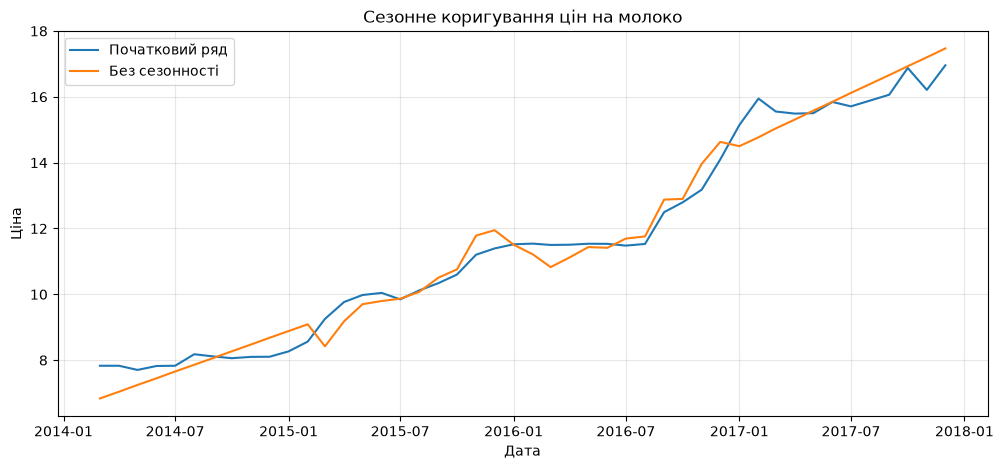

Кількість рядків: 46
Пропусків: 0
Файл збережено!


In [16]:
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt
import pandas as pd

stl_result = STL(ts_filled, period=12, robust=True).fit()

adjusted = ts_filled - stl_result.seasonal

plt.figure(figsize=(12, 5))
plt.plot(ts_filled.index, ts_filled, label="Початковий ряд")
plt.plot(adjusted.index, adjusted, label="Без сезонності")
plt.title("Сезонне коригування цін на молоко")
plt.xlabel("Дата")
plt.ylabel("Ціна")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

orange_data = pd.DataFrame({
    "date": ts_filled.index.strftime("%Y-%m-%d"),
    "price": ts_filled.values,
    "adjusted": adjusted.values
})

orange_data.to_csv(
    "ряд_сезонно_скоригований.csv",
    index=False,
    encoding="utf-8"
)

print("Кількість рядків:", len(orange_data))
print("Пропусків:", orange_data.isna().sum().sum())
print("Файл збережено!")


**Висновок до завдання 12:**

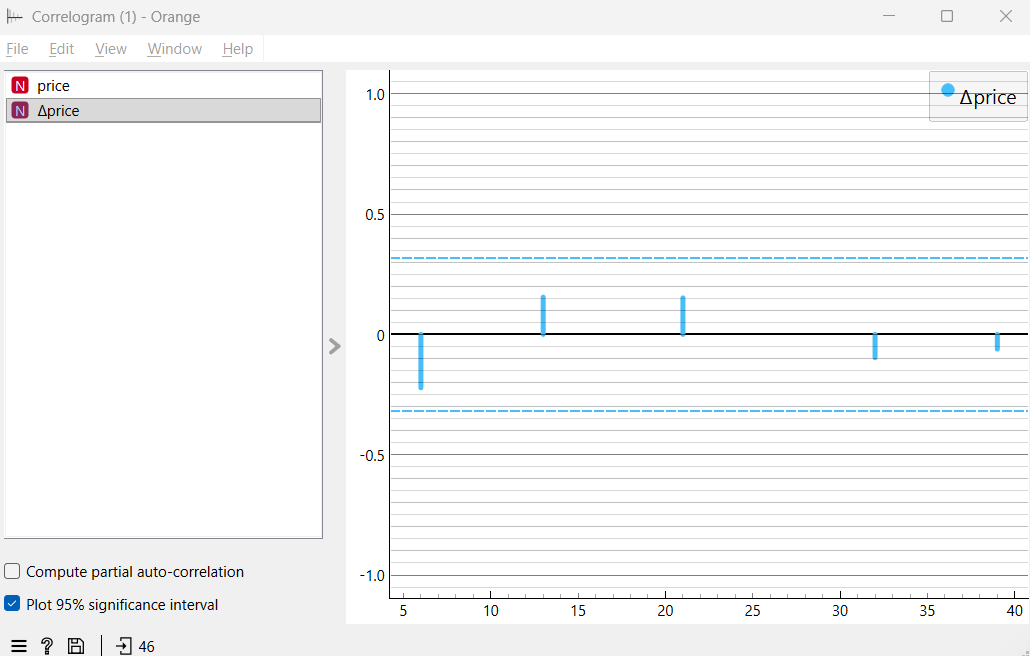

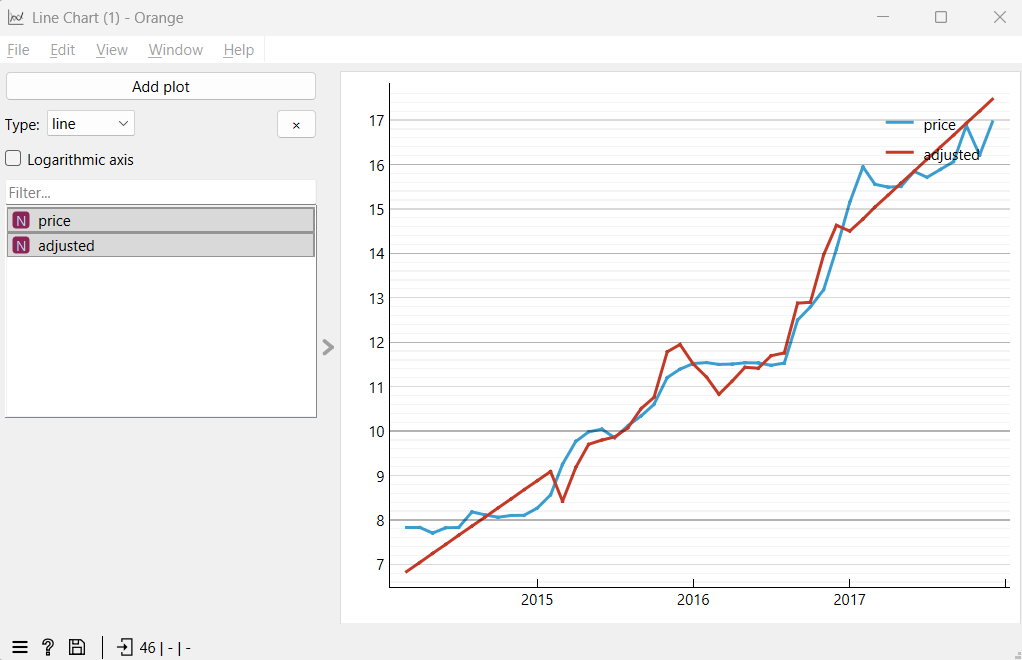

Корелограма підтвердила результати Python із завдання 5: після першого диференціювання значущої автокореляції не виявлено. Сезонне коригування виконано методом STL у Python через помилку віджета Orange. Скоригований ряд зберігає висхідний тренд. Сезонність слабка (Fs = 0.3490), що узгоджується із завданням 4.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

**Висновок до завдання 13:**

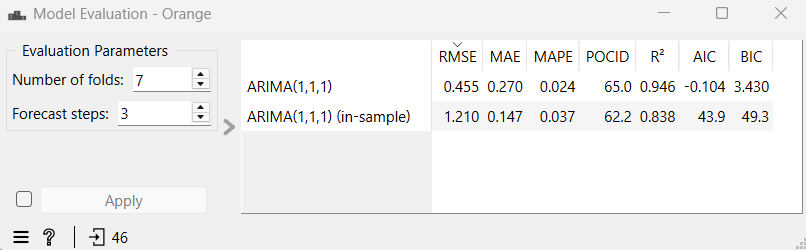

В Orange оцінено ARIMA(1,1,1) на 7 фолдах по 3 місяці. Отримано RMSE = 0.455, MAE = 0.270, MAPE = 2.4%, R² = 0.946. При 20 фолдах виникає помилка через недостатню довжину ряду (46 місяців). Модель навчається на перших 25 місяцях, далі навчальна частина розширюється на 3 місяці. Перевіряються послідовні тримісячні періоди з квітня 2016 до грудня 2017 року.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [17]:
# Завдання 14. Чому числа не збігаються
import numpy as np
import pandas as pd
import warnings
from statsmodels.tsa.arima.model import ARIMA

series = ts_filled.to_numpy(dtype=float)
true_values = []
pred_values = []

for fold in range(1, 8):
    train_end = -fold * 3

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = ARIMA(series[:train_end], order=(1, 1, 1)).fit()

    forecast = model.forecast(steps=3)

    true_values.extend(series[train_end:train_end + 3] if train_end != -3 else series[-3:])
    pred_values.extend(forecast)

true_values = np.array(true_values)
pred_values = np.array(pred_values)

errors = true_values - pred_values

rmse = np.sqrt(np.mean(errors ** 2))
mae = np.median(np.abs(errors))
mape = np.mean(np.abs(errors)) / np.mean(np.abs(true_values))
pocid = 100 * np.mean(
    (np.diff(true_values) * np.diff(pred_values)) > 0
)

results = pd.DataFrame({
    "Метрика": ["RMSE", "MAE", "MAPE", "POCID"],
    "Orange": [0.455, 0.270, 0.024, 65.0],
    "Python": [rmse, mae, mape, pocid],
    "Формула": [
        "sqrt(mean((y - pred)^2))",
        "median(abs(y - pred))",
        "mean(abs(y - pred)) / mean(abs(y))",
        "100 * mean(diff(y) * diff(pred) > 0)"
    ]
})

display(results.round(3))

print("Звичайний MAE:", round(np.mean(np.abs(errors)), 4))
print("Звичайний MAPE (%):",
      round(np.mean(np.abs(errors / true_values)) * 100, 4))

print("RMSE збігається:",
      round(rmse, 3) == 0.455)
print("MAE збігається:",
      round(mae, 3) == 0.270)
print("MAPE збігається:",
      round(mape, 3) == 0.024)
print("POCID збігається:",
      round(pocid, 1) == 65.0)


,Метрика,Orange,Python,Формула
0,RMSE,0.455,0.455,sqrt(mean((y - pred)^2))
1,MAE,0.270,0.270,median(abs(y - pred))
2,MAPE,0.024,0.024,mean(abs(y - pred)) / mean(abs(y))
3,POCID,65.000,65.000,100 * mean(diff(y) * diff(pred) > 0)


Звичайний MAE: 0.3438
Звичайний MAPE (%): 2.3082
RMSE збігається: True
MAE збігається: True
MAPE збігається: True
POCID збігається: True


**Висновок до завдання 14:**

Відтворено всі чотири метрики Orange: RMSE = 0.455, MAE = 0.270, MAPE = 0.024, POCID = 65%. Метрика MAE не відповідає звичному визначенню, оскільки Orange використовує медіану замість середнього (0.3438). RMSE збігається одразу через однакову формулу. MAPE також має інший спосіб обчислення. Перед порівнянням інструментів потрібно перевіряти формули, одиниці вимірювання та метод оцінювання.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [18]:
# Завдання 15. Матриця напрямку зміни
import numpy as np
import pandas as pd

actual_change = np.diff(true_values)
pred_change = np.diff(pred_values)

matrix = pd.DataFrame(
    [
        [
            np.sum((actual_change > 0) & (pred_change > 0)),
            np.sum((actual_change > 0) & (pred_change < 0))
        ],
        [
            np.sum((actual_change < 0) & (pred_change > 0)),
            np.sum((actual_change < 0) & (pred_change < 0))
        ]
    ],
    index=["Фактично зросла", "Фактично впала"],
    columns=["Прогноз: зросла", "Прогноз: впала"]
)

display(matrix)

correct = np.sum(actual_change * pred_change > 0)
total = len(actual_change)
pocid = correct / total * 100

print("Правильних передбачень:", correct)
print("Усього порівнянь:", total)
print(f"POCID Python: {pocid:.1f}%")
print("POCID Orange: 65.0%")
print("Значення збігаються:", np.isclose(pocid, 65.0))

,Прогноз: зросла,Прогноз: впала
Фактично зросла,6,5
Фактично впала,2,7


Правильних передбачень: 13
Усього порівнянь: 20
POCID Python: 65.0%
POCID Orange: 65.0%
Значення збігаються: True


**Висновок до завдання 15:**

Побудовано матрицю 2×2: модель правильно передбачила 6 зростань і 7 падінь ціни, помилилася 7 разів. Точність напрямку становить 65% (13 із 20), що збігається з POCID в Orange. Модель може допомагати вирішувати, купувати зараз чи чекати, але її точність недостатня для надійних рішень. На відміну від MAE та RMSE, POCID оцінює напрямок зміни, а не величину похибки.

---
# Загальний висновок

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

У ході роботи проаналізовано часовий ряд цін на молоко в Житомирі за 2014-2017 роки. Встановлено, що сезонність слабка (Fs = 0.3490), а тренд виражений (Ft = 0.9762). Найкращим методом прогнозування виявилася ARIMA(1,1,1) з MAE = 0.3438, RMSE = 0.4548 та MAPE = 2.31%. Вона перевершила найкращий базисний метод дрейфу, який мав MAE = 0.4811. Точку зміни рівня ряду виявлено в січні 2017 року, коли середня ціна зросла з 10.1077 до 15.9319. Зміна статистично значуща, проте її частково можна пояснити загальним висхідним трендом. Метрики Python та Orange відрізнялися через різні формули обчислення MAE та MAPE. Зокрема, Orange використовує медіану абсолютних похибок замість середнього для MAE. Через невелику кількість спостережень (46 місяців) неможливо надійно встановити довгострокові закономірності та стабільну сезонність. Отже, модель придатна для короткострокового прогнозування, але її результати потребують обережної інтерпретації.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | ChatGPT (GPT-6) |
| Для яких саме завдань | 1-15 |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Python-код |
| Що ви змінили у згенерованому результаті й чому | Адаптував код до свого набору даних |
| Що з отриманого ви **перевірили самостійно** і яким способом |  Запустив код у Jupyter і перевірив |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Виникали проблеми із залежностями Python |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Н.Н.В.  Дата: 27.10.2026